In [96]:
import numpy as np
import pandas as pd
import glob
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.patheffects as pe
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from matplotlib.ticker import LogLocator, LogFormatter
from matplotlib.ticker import LogLocator, NullFormatter
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Ellipse
from mpl_toolkits.axes_grid1 import make_axes_locatable
from io import StringIO
import sys, os
sys.path.insert(0, os.path.abspath('../..'))
from constants import *
from functions import *

from scipy.stats import linregress

In [98]:
def R0(v_w, Mdot, v_st, n_ISM, mu_ISM, T_ISM):
    
    alpha_ISM = kB*T_ISM/(v_st**2. * mp * mu_ISM)
    rho_ISM = mp*n_ISM*mu_ISM
    
    R0 = np.sqrt(v_w*Mdot / (4.*np.pi*(1.+alpha_ISM)*rho_ISM*v_st**2.) )
    
    return R0

In [99]:
def R0_proj(R0, distance, incli):
    '''
    Angular distance in arcmin
    '''
    
    R0_proj = (R0/AU)/(distance/pc)/60.*np.cos(incli)
    return R0_proj

In [100]:
cmap = 'Reds'

# Vela X-1

In [101]:
ang_corr_deg = 4.6
ang_corr = np.deg2rad(ang_corr_deg)
cosd = 0.759786128
inclination_deg = 65.
inclination = np.deg2rad(inclination_deg)
incli = np.pi/2. - inclination

In [102]:
v_st = 90e5
n_ISM = 2.
mu_ISM = 0.615
T_ISM = 8e3
v_w = 700e5
Mdot = 1e-6*Msun_yr
distance = 2.02*kpc

In [103]:
R0_VX1 = R0(v_w, Mdot, v_st, n_ISM, mu_ISM, T_ISM)
R0_proj_VX1 = R0_proj(R0_VX1, distance, incli)

print(R0_VX1, R0_proj_VX1)

1.4419690227112865e+18 0.720799587779398


In [104]:
source_file = '../../../R0_proj_Vela_X-1.dat'

## Halpha

In [105]:
nu_avg_file = '../../../S_alpha_convmap_Vela_X-1.dat'

In [106]:
contour_levels = [20., 43.]
 
xlim = (-3, 3)
ylim = (-2.25, 2.25)
 
# tamaño del haz (beam) en arcmin
siz_x = 10. / 60.0
siz_y = 20. / 60.0

In [107]:
X, Y, Z = load_gridded_data(nu_avg_file)
Xr, Yr = rotate(X, Y, ang_corr, sign=+1)
 
try:
    src = np.atleast_2d(np.loadtxt(source_file))
    xs, ys = rotate(src[:, 0], src[:, 1], ang_corr, sign=-1)
except OSError:
    xs, ys = np.array([]), np.array([])
    
xs, ys = xs*np.cos(incli), ys*np.cos(incli)   
x0_proj_corr = R0_proj_VX1 * np.sin(-ang_corr)
y0_proj_corr = R0_proj_VX1 * np.cos(ang_corr)
print(xs, ys)

[-0.05834874] [0.72520665]


<ipython-input-108-5242ace276cd>:11: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('+').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax1.scatter(xs, ys, s=200, marker='+', facecolor='cyan',


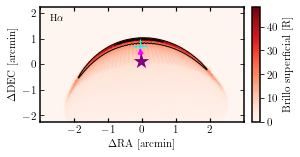

In [108]:
fig1, ax1 = plt.subplots(figsize=(0.6*text_width, 2./3.*0.6*text_width))
 
mesh = ax1.pcolormesh(Xr, Yr, Z, cmap=cmap, shading='auto')
mesh.set_rasterized(True)
 
# contours
cs = ax1.contour(Xr, Yr, Z, levels=contour_levels, colors='black', linewidths=1.)

if xs.size:
    ax1.scatter(xs, ys, s=200, marker='+', facecolor='cyan',
                edgecolor='black', linewidth=1.2, zorder=5)

ax1.annotate(
    '', xy=(x0_proj_corr, y0_proj_corr), xytext=(-0.01, 0.1),
    arrowprops=dict(arrowstyle='-|>', color='magenta', lw=1.8),
    zorder=6,
)

ax1.scatter([-0.01], [0.1], s=260, marker='*', facecolor='purple',
           edgecolor='none', zorder=6)

xlo, xhi = xlim
ylo, yhi = ylim
gx, gy = 0.92, 0.92
cx = xlo + gx * (xhi - xlo)
cy = ylo + gy * (yhi - ylo)

ax1.text(0.05, 0.9, r'H$\alpha$', transform=ax1.transAxes,
        ha='left', va='center', zorder=6, color='black')

ax1.set_xlim(*xlim)
ax1.set_ylim(*ylim)
ax1.set_xlabel(r'$\Delta$RA [arcmin]')
ax1.set_ylabel(r'$\Delta$DEC [arcmin]')
 
ax1.set_aspect((xhi - xlo) / (yhi - ylo) * (4.5 / 6.0) *
              ((yhi - ylo) / (xhi - xlo)))
 
ax1.xaxis.set_major_locator(plt.MultipleLocator(5))
ax1.xaxis.set_minor_locator(plt.MultipleLocator(1))
ax1.yaxis.set_major_locator(plt.MultipleLocator(5))
ax1.yaxis.set_minor_locator(plt.MultipleLocator(1))
ax1.set_xticks([-2,-1,0,1,2])
ax1.set_yticks([-2,-1,0,1,2])
ax1.tick_params(which='both', direction='in', top=True, right=True)

fig1.canvas.draw()
pos = ax1.get_position()
cbar_width = 0.03
cbar_pad = 0.03
cbar_corr = 0.0
cax = fig1.add_axes([pos.x1 + cbar_pad, pos.y0 + cbar_corr, cbar_width, pos.height])
cbar = fig1.colorbar(mesh, cax=cax)
cbar.set_label('Brillo superficial [R]')

plt.show()


# Save figs

In [110]:
from matplotlib.transforms import Bbox

def tight_bbox(fig, pad=0.01):
    bbox = fig.get_tightbbox(fig.canvas.get_renderer())
    return bbox.padded(pad)

bbox1 = tight_bbox(fig1)

common_bbox = Bbox.union([bbox1])


fig1.savefig('map_Vela_X-1.pdf',  bbox_inches=common_bbox)